# Credit Card Fraud Detection

**Question:** Given an anonymised card transaction, how well can we tell whether it's fraud, and where should we set the alert threshold so that it pays off?

**Data:** [Kaggle / ULB credit card fraud dataset](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud). It covers two days of European card transactions from September 2013. `V1`–`V28` are PCA components (the original features are confidential), plus `Time`, `Amount` and the label `Class`.

This notebook runs on the committed 5% random sample (`data/creditcard_sample.csv`) out of the box. If you download the full `creditcard.csv` into `data/`, it is used automatically and every number below is recomputed.

**What this analysis is careful about:**
1. **Metrics that respect the imbalance.** Fraud is about 0.15% of rows, so accuracy is meaningless. I use **PR-AUC** (average precision) as the headline metric.
2. **No leakage.** Scaling and SMOTE live inside the model pipeline, so they are fit on training folds only. No feature selection is done on the full data.
3. **Honest uncertainty.** With few fraud cases, one train/test split is mostly luck. I use 5-fold cross-validation repeated 3 times and report the spread as well as the mean.
4. **A decision, not just a score.** I pick the alert threshold by money saved, not by a default of 0.5.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from sklearn.metrics import PrecisionRecallDisplay

from fraud import (add_features, compare_models, load_data, make_models,
                   out_of_fold_scores, split_xy, threshold_table)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)

def save(name):
    plt.savefig(FIG / name, dpi=120, bbox_inches="tight")

/usr/local/lib/python3.11/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Data

In [2]:
raw = load_data(ROOT / "data")
df = add_features(raw)
X, y = split_xy(df)

print(f"Source file:   {raw.attrs['source']}")
print(f"Transactions:  {len(df):,}")
print(f"Fraud cases:   {y.sum():,}  ({y.mean():.3%})")
print(f"Model features: {X.shape[1]}")

Source file:   creditcard_sample.csv
Transactions:  14,240
Fraud cases:   21  (0.147%)
Model features: 31


That fraud count is the most important number in the notebook. **On the 5% sample there are only a couple dozen frauds.** Every metric below is estimated from that handful, so treat it as a demonstration of the method, with wide error bars. On the full dataset (492 frauds) the same code gives much more stable estimates.

## 2. Exploratory analysis

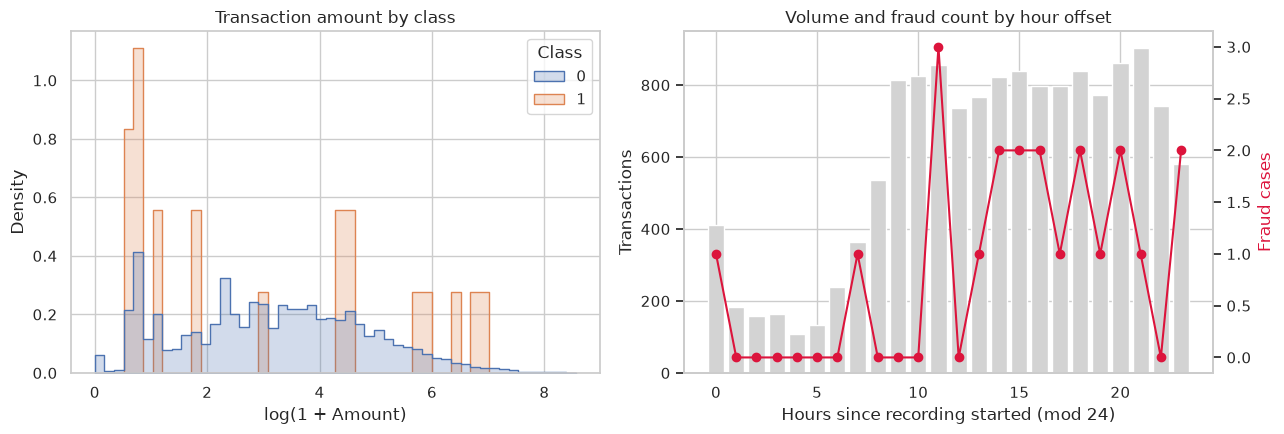

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(data=df, x="LogAmount", hue="Class", stat="density", common_norm=False,
             bins=50, element="step", ax=axes[0])
axes[0].set(title="Transaction amount by class", xlabel="log(1 + Amount)")

hour = (raw["Time"] // 3600) % 24
by_hour = pd.DataFrame({"hour": hour, "fraud": y}).groupby("hour")["fraud"].agg(["size", "sum"])
axes[1].bar(by_hour.index, by_hour["size"], color="lightgray", label="All transactions")
ax2 = axes[1].twinx()
ax2.plot(by_hour.index, by_hour["sum"], "o-", color="crimson", label="Fraud cases")
axes[1].set(title="Volume and fraud count by hour offset", xlabel="Hours since recording started (mod 24)", ylabel="Transactions")
ax2.set_ylabel("Fraud cases", color="crimson")
ax2.grid(False)
plt.tight_layout(); save("eda_amount_and_hour.png"); plt.show()

**Reading the plots**
- **Amount:** fraudulent amounts are spread differently from legitimate ones and are heavier at very small values. That's consistent with "card testing", where a stolen card is tried with a tiny charge first. Amount on its own is a weak separator, though.
- **Hour:** `Time` counts seconds from the first transaction, *not* the clock time. The deep trough in volume is very likely night-time, but we can't name actual hours. Fraud counts per hour are tiny on the sample, so I don't read hour-by-hour spikes as real patterns. The hour is still given to the models as a cyclical sin/cos feature.
- `V1`–`V28` are PCA components with no business meaning. We can say *which* components matter, not *why*.

## 3. Model comparison (repeated stratified cross-validation)

Five candidates, from a no-skill baseline up to tree ensembles. A model is useful only if it clearly beats the baseline's PR-AUC, which equals the fraud rate.

In [4]:
models = make_models()
results = compare_models(models, X, y, n_splits=5, n_repeats=3)
results.round(3)

,pr_auc_mean,pr_auc_std,roc_auc_mean,roc_auc_std
model,,,,
Random forest,0.653,0.267,0.920,0.097
Random forest + SMOTE,0.623,0.245,0.946,0.098
Logistic regression,0.463,0.226,0.834,0.163
Gradient boosting,0.461,0.240,0.857,0.141
Baseline (always 'not fraud'),0.001,0.000,0.500,0.000


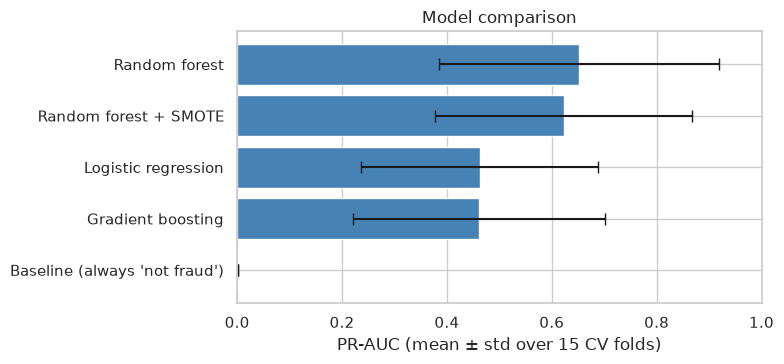

In [5]:
plot_df = results.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(plot_df.index, plot_df["pr_auc_mean"], xerr=plot_df["pr_auc_std"], color="steelblue", capsize=4)
ax.set(xlabel="PR-AUC (mean ± std over 15 CV folds)", xlim=(0, 1), title="Model comparison")
plt.tight_layout(); save("model_comparison.png"); plt.show()

**Takeaways**
- Every real model is far above the baseline. The tree ensembles rank fraud best.
- **SMOTE did not help** the random forest. Giving the rare class more weight (`class_weight="balanced_subsample"`) does the same job without inventing synthetic points.
- The error bars are wide. Some folds contain only 4 frauds, so catching or missing one moves the score a lot. Differences between neighbouring models may not be real; differences from the baseline are.

## 4. Precision–recall trade-off

To look at curves without cheating, each transaction is scored by a model trained on the *other* folds (out-of-fold predictions).

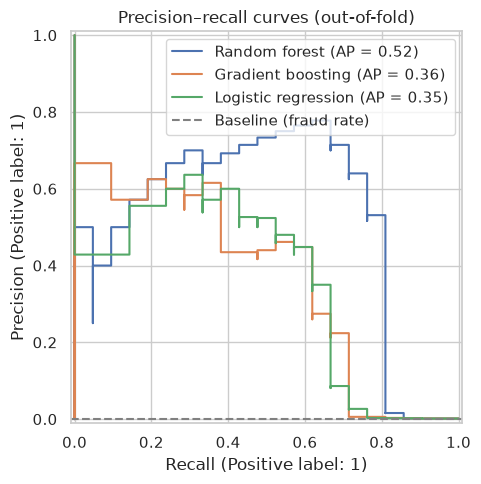

In [6]:
contenders = ["Random forest", "Gradient boosting", "Logistic regression"]
oof = {name: out_of_fold_scores(models[name], X, y) for name in contenders}

fig, ax = plt.subplots(figsize=(7, 5))
for name, s in oof.items():
    PrecisionRecallDisplay.from_predictions(y, s, name=name, ax=ax)
ax.axhline(y.mean(), ls="--", color="gray", label="Baseline (fraud rate)")
ax.set(title="Precision–recall curves (out-of-fold)")
ax.legend(loc="upper right")
plt.tight_layout(); save("pr_curves.png"); plt.show()

## 5. Choosing an alert threshold by money saved

A default cut-off of 0.5 is arbitrary. Here is a simple cost model:
- every flagged transaction is reviewed by an analyst at an assumed **\$5 per review**;
- every caught fraud prevents a loss equal to its `Amount`.

Net savings = fraud amount caught − review cost. We sweep the threshold and pick the one that maximises it.

> Caveat: the threshold is chosen and scored on the same out-of-fold predictions, so the savings figure is optimistic. In production you would pick it on a validation period and confirm it on a later one.

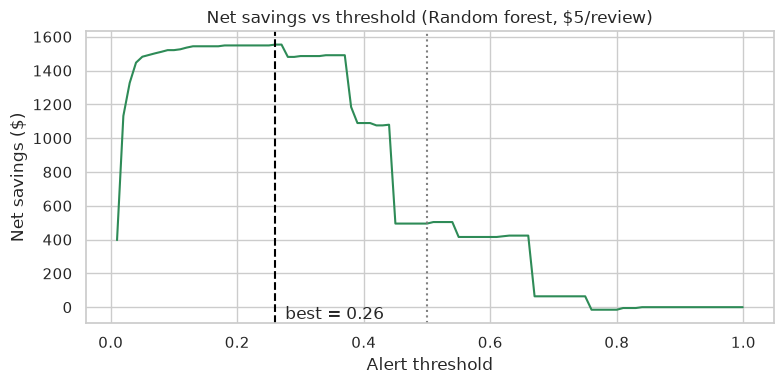

,flagged,frauds_caught,frauds_missed,false_alarms,fraud_amount_caught,review_cost,net_savings
threshold,,,,,,,
best (0.26),21,15,6,6,1658.59,105.0,1553.59
default (0.50),11,7,14,4,549.65,55.0,494.65


In [7]:
REVIEW_COST = 5.0
best_name = results.drop(index=[i for i in results.index if "Baseline" in i]).index[0]
table = threshold_table(y, oof[best_name], df["Amount"], review_cost=REVIEW_COST)
best_t = table["net_savings"].idxmax()

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(table.index, table["net_savings"], color="seagreen")
ax.axvline(best_t, ls="--", color="black")
ax.axvline(0.5, ls=":", color="gray")
ax.text(best_t, ax.get_ylim()[0], f"  best = {best_t:.2f}", va="bottom")
ax.set(title=f"Net savings vs threshold ({best_name}, ${REVIEW_COST:.0f}/review)",
       xlabel="Alert threshold", ylabel="Net savings ($)")
plt.tight_layout(); save("threshold_savings.png"); plt.show()

summary = table.loc[[best_t, 0.5]].rename(index={best_t: f"best ({best_t:.2f})", 0.5: "default (0.50)"})
summary[["flagged", "frauds_caught", "frauds_missed", "false_alarms",
         "fraud_amount_caught", "review_cost", "net_savings"]].round(2)

In [8]:
total = df.loc[y == 1, "Amount"].sum()
row = table.loc[best_t]
print(f"Total fraud amount in data:     ${total:,.2f}")
print(f"Caught at best threshold:       ${row.fraud_amount_caught:,.2f} ({row.fraud_amount_caught / total:.0%})")
print(f"Transactions sent to review:    {int(row.flagged)} of {len(df):,} ({row.flagged / len(df):.2%})")

Total fraud amount in data:     $3,589.66
Caught at best threshold:       $1,658.59 (46%)
Transactions sent to review:    21 of 14,240 (0.15%)


In this setup, the optimal threshold sits well below 0.5. Reviews are cheap compared with a missed fraud, so it pays to flag more aggressively. Change `REVIEW_COST` to see how the best threshold moves.

## 6. What drives the random forest? (SHAP)

SHAP splits each prediction into per-feature contributions. Explaining every row would be slow, so I explain all fraud cases plus a random set of legitimate ones.

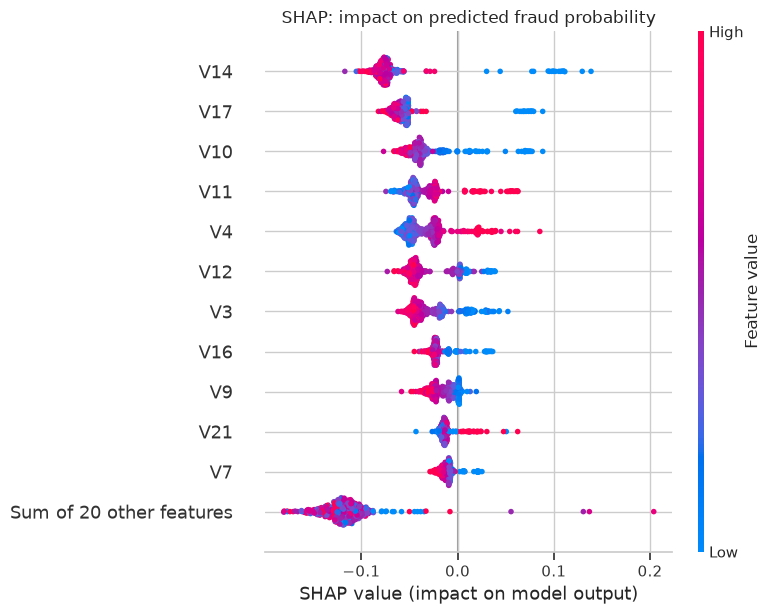

In [9]:
rf = models["Random forest"].fit(X, y)["clf"]
X_explain = pd.concat([X[y == 1], X[y == 0].sample(500, random_state=42)])
sv = shap.TreeExplainer(rf)(X_explain)[..., 1]

shap.plots.beeswarm(sv, max_display=12, show=False)
plt.title("SHAP: impact on predicted fraud probability")
plt.tight_layout(); save("shap_summary.png"); plt.show()

**Reading the beeswarm:** each dot is one transaction. Dots to the right push toward "fraud". Colour shows whether the feature value was high (red) or low (blue). On the sample, the same few components (typically `V14`, `V10`, `V12`, `V4`, `V17`) dominate, and *low* values of most of them signal fraud. That matches published analyses of the full dataset. Because the `V`s are anonymised PCA components, this tells us where the model looks, not *why* in business terms.

## 7. Conclusions and limitations

- **Tree ensembles beat logistic regression** on PR-AUC. The plain random forest with class weights was as good as or better than SMOTE.
- **The threshold is a business decision.** Optimising for money saved gives a very different cut-off from the default 0.5.
- **Sample size is the main limitation.** With only a couple dozen frauds in the sample, all estimates are noisy. Run on the full dataset for numbers you can quote.
- **Time ordering.** Real fraud systems are trained on the past and tested on the future. A time-based split (train on day 1, test on day 2) is the natural next step with the full data.
- **Possible extensions:** probability calibration, a time-based validation split, and per-transaction review costs that scale with amount.